In [ ]:
# 목적 : 마케팅 프로젝트 + 데이터 프로젝트 : 고객 & 시장조사 필수 
# 문제인식, 정의, 솔루션, 전략수립, 고객 구체화 
# SNS : 인스타그램, 유튜브 
# 가져온 정보 : 영상컨텐츠, 스탯정보, 댓글정보

In [19]:
import pandas as pd 

df_stats = pd.read_csv("data/youtube_stats_20261106_112057.csv", encoding="utf-8-sig")
df_comments = pd.read_csv("data/youtube_comments_20261106_112057.csv", encoding="utf-8-sig")
df_final = pd.read_csv("data/youtube_final_20261106_112057.csv", encoding="utf-8-sig")

print("영상 데이터:", df_stats.shape) # 찾아온 해당 데이터프레임이 몇행.몇열 (데이터의 크기)
print("댓글 데이터:", df_comments.shape)
print("통합 데이터:", df_final.shape)

영상 데이터: (30, 9)
댓글 데이터: (124, 6)
통합 데이터: (145, 14)


In [20]:
# 데이터 관련 작업 : ctrl + z 안되

videos = df_stats.copy()
comments = df_comments.copy()

comments = comments.dropna(subset=["comment_id","comment"])
comments = comments.drop_duplicates(subset=["comment_id"])

comments["comment"] = comments["comment"].astype(str)

comments["comment_published_at"] = pd.to_datetime(
    comments["comment_published_at"],
    errors="coerce",
    utc=True
).dt.tz_convert("Asia/Seoul")

print("분석 대상 영상:", len(videos))
print("분석 대상 댓글:", len(comments))


분석 대상 영상: 30
분석 대상 댓글: 124


In [21]:
videos.head()

,video_id,title,description,channel,published_at,published_at_Seoul,view_count,like_count,comment_count
0,f6-a5qzExsQ,🧙🏻‍♂️해피 할로윈 배라!🍨 배스킨라빈스 버라이어티팩 6팩 마법사의비밀레시피/엄마...,안녕하세요! ⭐️먹텔라⭐️입니다. 오늘은 할로윈 시즌을 맞아 [배스킨라빈스]에서 시...,🍔먹텔라의 한끼🍔,2026-10-31T12:00:39Z,2026-10-31 21:00:39+09:00,226,NaN,9
1,nuM7kir_N8Y,바나나 스플릿 먹어본사람~,배스킨라빈스#배라 #알바 #알바생 #아이스크림 #혼종 #바나나스플릿 #딸기 #바나나...,독고박사,2026-10-31T10:41:47Z,2026-10-31 19:41:47+09:00,12201,60.0,2
2,kFhjKqIhwkc,#유명한 #연예인 #VVVIP #배스킨라빈스 #유튜버장애인 #추천 #추천떠라 #릴스...,NaN,VVVIP,2026-10-31T10:24:23Z,2026-10-31 19:24:23+09:00,2,1.0,0
3,njEe4dz2rtQ,#유명한 #연예인 #VVVIP #배스킨라빈스 #유튜버장애인 #추천 #추천떠라 #릴스...,NaN,VVVIP,2026-10-31T10:01:47Z,2026-10-31 19:01:47+09:00,5,2.0,0
4,cHB0hNFa68Q,배스킨라빈스 11월 신메뉴!.!🫪호빵맨콜라보로 나온쿠키맛!.!🩷배스킨라빈스 신메뉴 ...,배스킨라빈스 신메뉴 11월이달의맛 도우와줘요호빵맨 먹방(10월 30일) 배스킨라빈스...,먹효니,2026-10-31T09:33:47Z,2026-10-31 18:33:47+09:00,300,6.0,0


In [6]:
comments.info()

# ns : nanosecond = 나노초
# us : microsecond = 마이크로초 
# 동일한 시간을 표기하는데 있어서 : 시간의 정밀도가 ns > us : 1000배 정도 더 정밀한 시간
# 국제표준시 -> 한국시간 : 9시간 (연산 ->마이크로초 소수점 6번째 자리까지, 나노초 9번째 자리까지)

<class 'pandas.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype                     
---  ------                --------------  -----                     
 0   video_id              42 non-null     str                       
 1   comment_id            42 non-null     str                       
 2   author                42 non-null     str                       
 3   comment               42 non-null     str                       
 4   comment_like_count    42 non-null     int64                     
 5   comment_published_at  42 non-null     datetime64[us, Asia/Seoul]
dtypes: datetime64[us, Asia/Seoul](1), int64(1), str(4)
memory usage: 6.1 KB


In [22]:
videos["like_rate"] = videos["like_count"] / videos["view_count"] * 100
videos["comment_rate"] = videos["comment_count"] / videos["view_count"] * 100
videos["engagement_rate"] = videos["like_count"] + videos["comment_count"] / videos["view_count"] * 100

In [23]:
videos.head()

,video_id,title,description,channel,published_at,published_at_Seoul,view_count,like_count,comment_count,like_rate,comment_rate,engagement_rate
0,f6-a5qzExsQ,🧙🏻‍♂️해피 할로윈 배라!🍨 배스킨라빈스 버라이어티팩 6팩 마법사의비밀레시피/엄마...,안녕하세요! ⭐️먹텔라⭐️입니다. 오늘은 할로윈 시즌을 맞아 [배스킨라빈스]에서 시...,🍔먹텔라의 한끼🍔,2026-10-31T12:00:39Z,2026-10-31 21:00:39+09:00,226,NaN,9,NaN,3.982301,NaN
1,nuM7kir_N8Y,바나나 스플릿 먹어본사람~,배스킨라빈스#배라 #알바 #알바생 #아이스크림 #혼종 #바나나스플릿 #딸기 #바나나...,독고박사,2026-10-31T10:41:47Z,2026-10-31 19:41:47+09:00,12201,60.0,2,0.491763,0.016392,60.016392
2,kFhjKqIhwkc,#유명한 #연예인 #VVVIP #배스킨라빈스 #유튜버장애인 #추천 #추천떠라 #릴스...,NaN,VVVIP,2026-10-31T10:24:23Z,2026-10-31 19:24:23+09:00,2,1.0,0,50.000000,0.000000,1.000000
3,njEe4dz2rtQ,#유명한 #연예인 #VVVIP #배스킨라빈스 #유튜버장애인 #추천 #추천떠라 #릴스...,NaN,VVVIP,2026-10-31T10:01:47Z,2026-10-31 19:01:47+09:00,5,2.0,0,40.000000,0.000000,2.000000
4,cHB0hNFa68Q,배스킨라빈스 11월 신메뉴!.!🫪호빵맨콜라보로 나온쿠키맛!.!🩷배스킨라빈스 신메뉴 ...,배스킨라빈스 신메뉴 11월이달의맛 도우와줘요호빵맨 먹방(10월 30일) 배스킨라빈스...,먹효니,2026-10-31T09:33:47Z,2026-10-31 18:33:47+09:00,300,6.0,0,2.000000,0.000000,6.000000


In [24]:
# kiwipiepy : 어떤 문장 -> 단어 형태를 추출 -> 해당 단어가 얼만큼 사용
# M/L : 특정 문장 -> 단순히 단어 사용량, 어떤 단어가 대표적인 단어인가, 긍정과 부정의 늬앙스의 단어 분류 가능

%pip install kiwipiepy

Note: you may need to restart the kernel to use updated packages.


In [10]:
from kiwipiepy import Kiwi

kiwi = Kiwi()

text = "쿠팡플레이에서 재미있는 영상을 시청했습니다."

tokens = kiwi.tokenize(text)

for token in tokens:
    print(token.form, token.tag)

쿠팡 NNP
플레이 NNG
에서 JKB
재미있 VA
는 ETM
영상 NNG
을 JKO
시청 NNG
하 XSV
었 EP
습니다 EF
. SF


- **NNP : Noun Proper : 고유명사 = 서울, 대한민국
- **NNG : Noun General : 일반명사 = 데이터, 마케팅
- JKB : Josa, Kyeok, Busa : 부사격 조사 = 에, 에서
- JKO : Josa, Kyeok, Object : 목적격 조사 = 을, 를 
- **VA : Verb, Adjective: 형용사 : 좋다, 빠르다
- ETM : 연결 어미
- XSV : 명사 파생 접미사
- EP : 선어말 어미 : 었, 겠
- EF : 종결 어미
- SF : 문장 부호

In [11]:
import pandas as pd 
import sys

print("python:", sys.version)
print("pandas:", pd.__version__)

python: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
pandas: 3.0.3


In [25]:
# 분석 해야할 대상 : 댓글 분석 =>
# 1) 특정 사이트 및 페이지 URL : http~~~~
# 2) \n, \t, \r 추가
# 3) 특수 문자
# 4) 여백


comments.head()

,video_id,comment_id,author,comment,comment_like_count,comment_published_at
0,f6-a5qzExsQ,Ugzt-gwbcLJlB9j99c54AaABAg,@loboincel-007,Happy Halloween 🎃 ❤,0,2026-11-01 02:27:09+09:00
1,f6-a5qzExsQ,UgzbCa6uyRKsb2Po6N14AaABAg,@아기댕댕이-z5n,매운거 잘못먹는 분들을위한 불닭볶음면 레시피가 있네요.멸치칼국수와 섞어 먹는겁니다.,1,2026-11-01 02:20:11+09:00
2,f6-a5qzExsQ,Ugx1qc0OWTI2belnyEJ4AaABAg,@axlrose2886,Ciao bella 👋🏻👋🏻👋🏻😍😍😍😍buon Halloween 🎃 👻 il ge...,0,2026-10-31 22:39:01+09:00
3,f6-a5qzExsQ,UgyZ4ZBoJhpEgc_I0pd4AaABAg,@송승헌-f1i,내가조아하는거내요 ㅜ사무야지,1,2026-10-31 21:53:22+09:00
4,f6-a5qzExsQ,Ugx79jUZYtMT7DUSbLR4AaABAg,@Stella0112,중간부터 몸 떨리는 증상은 추운날에 차가운걸 먹어서 체온이 잠시 낮아진 흔한 반응이...,3,2026-10-31 21:25:09+09:00


In [26]:
# 정규표현식 = regular expression
# r : raw string 약어 -> \s와 같은 문자열 => 원시타입 문자가 존재한다면, 해당 문자열 인정 해석 역할 
# ? : 존재할 수도 있고, 존재하지 않을 수도 있음을 의미
# \S : 공백이 아닌 문자 : non white space 
# \s : 공백인 문자 : white space 
# + : 앞에 입력된 형태의 요소가 1개 이상 반복할 수 있음을 의미
# [] : 문자열 클래스를 생성해서 해당 클래스 안에 겹치는 요소가 1개라도 존재한다면, in[] 
# ^ : [^] : 반대 = 부정, ^[] : ~으로 시작한다는 의미  
# 정제작업을 했다

import re 

def clean_text(text):

    text = str(text)

    text = re.sub(r"https?://\S+", " ", text)

    text = re.sub(r"[\n\r\t]+", " ", text)

    text = re.sub(r"[^가-힣a-zA-Z0-9\s]", " ", text)

    text = re.sub(r"\s+", " ", text).strip()

    return text 

comments["clean_comment"] = comments["comment"].apply(clean_text)
comments[["comment", "clean_comment"]].head(10)

    

,comment,clean_comment
0,Happy Halloween 🎃 ❤,Happy Halloween
1,매운거 잘못먹는 분들을위한 불닭볶음면 레시피가 있네요.멸치칼국수와 섞어 먹는겁니다.,매운거 잘못먹는 분들을위한 불닭볶음면 레시피가 있네요 멸치칼국수와 섞어 먹는겁니다
2,Ciao bella 👋🏻👋🏻👋🏻😍😍😍😍buon Halloween 🎃 👻 il ge...,Ciao bella buon Halloween il gelato delizioso
3,내가조아하는거내요 ㅜ사무야지,내가조아하는거내요 사무야지
4,중간부터 몸 떨리는 증상은 추운날에 차가운걸 먹어서 체온이 잠시 낮아진 흔한 반응이...,중간부터 몸 떨리는 증상은 추운날에 차가운걸 먹어서 체온이 잠시 낮아진 흔한 반응이...
5,???: 여기 땅콩들어갔잖아요! 환불해주세요!,여기 땅콩들어갔잖아요 환불해주세요
6,먹텔라 헤메코 왜이리 귀엽냐아옹~,먹텔라 헤메코 왜이리 귀엽냐아옹
7,귀엽고 이쁜 텔라님😍 검은냥이 제가 키우고싶네요,귀엽고 이쁜 텔라님 검은냥이 제가 키우고싶네요
8,Happy Halloween 🎃♥️,Happy Halloween
9,Enak banget🤤🤤Apalagi yang cokelat🍫😊,Enak banget Apalagi yang cokelat


In [27]:
def extract_nouns(text):

    tokens = kiwi.tokenize(text) 
    
    # 리스트라는 자료구조 안에서 for in 사용, 반복문을 통해서 추출된 값들을 바로 리스크화 = 리스트 컴프리핸션
    nouns = [token.form for token in tokens if token.tag in ["NNG", "NNP", "VA"] and len(token.form) >= 2]

    return nouns

comments["nouns"] = comments["clean_comment"].apply(extract_nouns)

pd.set_option("display.max_rows", None) 

comments[["clean_comment", "nouns"]] 

,clean_comment,nouns
0,Happy Halloween,[]
1,매운거 잘못먹는 분들을위한 불닭볶음면 레시피가 있네요 멸치칼국수와 섞어 먹는겁니다,"[불닭볶음면, 레시피, 멸치, 칼국수]"
2,Ciao bella buon Halloween il gelato delizioso,[]
3,내가조아하는거내요 사무야지,[사무야지]
4,중간부터 몸 떨리는 증상은 추운날에 차가운걸 먹어서 체온이 잠시 낮아진 흔한 반응이...,"[중간, 증상, 체온, 흔하, 반응, 건강, 문제]"
5,여기 땅콩들어갔잖아요 환불해주세요,"[땅콩, 환불]"
6,먹텔라 헤메코 왜이리 귀엽냐아옹,"[먹텔라, 헤메코]"
7,귀엽고 이쁜 텔라님 검은냥이 제가 키우고싶네요,"[이쁘, 텔라님]"
8,Happy Halloween,[]
9,Enak banget Apalagi yang cokelat,[]


In [28]:
# 키위 -> 문장 -> 명사 추출 -> 특정 불필요한 단어, 키워드 배제 

# 불용어 = stopword

stopwords = {
    
    
}

def remove_stopwords(words):

    return [word for word in words if word not in stopwords]

comments["filtered_nouns"] = comments["nouns"].apply(remove_stopwords)

comments

,video_id,comment_id,author,comment,comment_like_count,comment_published_at,clean_comment,nouns,filtered_nouns
0,f6-a5qzExsQ,Ugzt-gwbcLJlB9j99c54AaABAg,@loboincel-007,Happy Halloween 🎃 ❤,0,2026-11-01 02:27:09+09:00,Happy Halloween,[],[]
1,f6-a5qzExsQ,UgzbCa6uyRKsb2Po6N14AaABAg,@아기댕댕이-z5n,매운거 잘못먹는 분들을위한 불닭볶음면 레시피가 있네요.멸치칼국수와 섞어 먹는겁니다.,1,2026-11-01 02:20:11+09:00,매운거 잘못먹는 분들을위한 불닭볶음면 레시피가 있네요 멸치칼국수와 섞어 먹는겁니다,"[불닭볶음면, 레시피, 멸치, 칼국수]","[불닭볶음면, 레시피, 멸치, 칼국수]"
2,f6-a5qzExsQ,Ugx1qc0OWTI2belnyEJ4AaABAg,@axlrose2886,Ciao bella 👋🏻👋🏻👋🏻😍😍😍😍buon Halloween 🎃 👻 il ge...,0,2026-10-31 22:39:01+09:00,Ciao bella buon Halloween il gelato delizioso,[],[]
3,f6-a5qzExsQ,UgyZ4ZBoJhpEgc_I0pd4AaABAg,@송승헌-f1i,내가조아하는거내요 ㅜ사무야지,1,2026-10-31 21:53:22+09:00,내가조아하는거내요 사무야지,[사무야지],[사무야지]
4,f6-a5qzExsQ,Ugx79jUZYtMT7DUSbLR4AaABAg,@Stella0112,중간부터 몸 떨리는 증상은 추운날에 차가운걸 먹어서 체온이 잠시 낮아진 흔한 반응이...,3,2026-10-31 21:25:09+09:00,중간부터 몸 떨리는 증상은 추운날에 차가운걸 먹어서 체온이 잠시 낮아진 흔한 반응이...,"[중간, 증상, 체온, 흔하, 반응, 건강, 문제]","[중간, 증상, 체온, 흔하, 반응, 건강, 문제]"
5,nuM7kir_N8Y,UgxRoP4r7IEmiNN0Gid4AaABAg,@캐리얼-1327,???: 여기 땅콩들어갔잖아요! 환불해주세요!,0,2026-11-01 15:57:44+09:00,여기 땅콩들어갔잖아요 환불해주세요,"[땅콩, 환불]","[땅콩, 환불]"
6,o-PLxaQCTto,Ugy4vA2kFTcEbXBHIzJ4AaABAg,@아기댕댕이-z5n,먹텔라 헤메코 왜이리 귀엽냐아옹~,1,2026-11-02 14:50:39+09:00,먹텔라 헤메코 왜이리 귀엽냐아옹,"[먹텔라, 헤메코]","[먹텔라, 헤메코]"
7,o-PLxaQCTto,UgwChpvxDGZV8Njy44Z4AaABAg,@발챙발챙,귀엽고 이쁜 텔라님😍 검은냥이 제가 키우고싶네요,0,2026-11-02 01:32:08+09:00,귀엽고 이쁜 텔라님 검은냥이 제가 키우고싶네요,"[이쁘, 텔라님]","[이쁘, 텔라님]"
8,o-PLxaQCTto,UgyiHm6FIQRPlFDubQJ4AaABAg,@loboincel-007,Happy Halloween 🎃♥️,0,2026-11-01 02:26:50+09:00,Happy Halloween,[],[]
9,o-PLxaQCTto,Ugz4GmlKVvFzGthBKPF4AaABAg,@kangkomen955,Enak banget🤤🤤Apalagi yang cokelat🍫😊,0,2026-10-31 22:36:05+09:00,Enak banget Apalagi yang cokelat,[],[]


In [29]:
from collections import Counter

all_words = [word for words in comments["filtered_nouns"] for word in words]

word_counts = Counter(all_words)

df_words = pd.DataFrame(
    word_counts.most_common(30),
    columns=["word", "frequency"]
)
df_words

,word,frequency
0,아이스크림,20
1,가격,19
2,비싸,14
3,베라,8
4,배달,8
5,생각,7
6,사람,7
7,매장,7
8,베스킨라빈스,7
9,건강,6


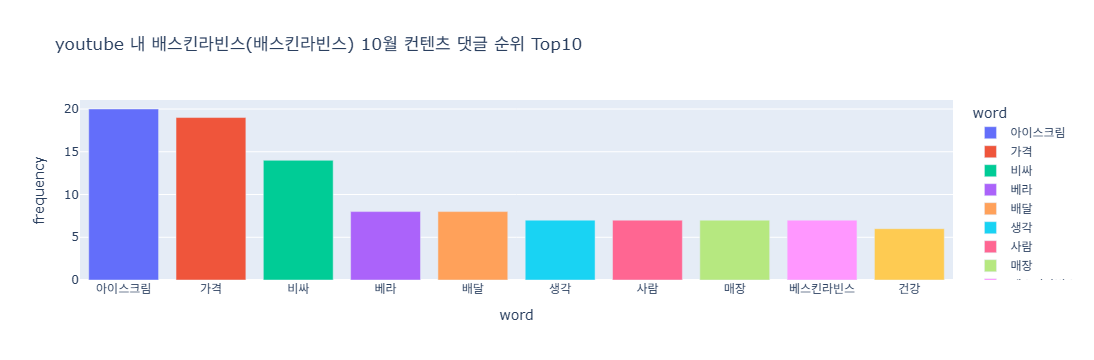

In [31]:
import plotly.express as px

top10 = df_words.head(10).sort_values("frequency", ascending=False)

fig = px.bar(
    top10,
    x="word",
    y="frequency",
    title="youtube 내 배스킨라빈스(배스킨라빈스) 10월 컨텐츠 댓글 순위 Top10",
    color="word"
)

fig.show()